# 10. Across the six datasets: does the curved share say when flexible models catch more?

**The question** (the project's main question since the decision of 16 November): measured on normal data alone, does the curved share predict when flexible and deep models catch more faults than straight-line ones?

**The six datasets**, each as its own notebook set it up: the water pump (SKAB, notebooks 02 and 04), the chemical plant at one setting (Rieth runs, notebooks 03 and 04), the Cranfield flow rig (05), the chemical plant in six modes (06), the metal etcher (07) and the IndPenSim penicillin batches (08). The deep models come from notebook 09.

**Six datasets make a picture, not a test.** With six points, a pattern can easily come from chance or from how the datasets differ in other ways. So this notebook gives the numbers, a chart and a simple count, and no verdict.

**One new measure, the kinked share.** A straight-line model can be given corners: each input sensor also enters as "how far above its 10th, 50th and 90th percentile" it is (zero below), then the same straight-line fit. This *kinked straight model* takes the flexible model's place in each dataset's headline measure, with the same hold-out rounds. Its gain over the plain straight model is the **kinked gain**; the **kinked share** is that gain over the curved share: how much of the curve a few corners recover. The same kinked model is also a detector, the **kinked-link residual**, scored like the straight-link one.

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import warnings
import pandas as pd

from adlab import across, explore, plots

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", explore.tidy)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 90)

## 1. The curved share and the kinked share

*The kinked measure was added on 16 November, before it was computed on any dataset.* The curved share is each dataset's headline from its own notebook, read back from `results/cache`, unchanged.

In [2]:
frame = across.table()           # the first time, the kinked measure takes about 15 minutes; then read from results/cache
frame[["curved share", "curved low", "curved high", "kinked gain", "kinked low", "kinked high", "kinked share of the curve"]]

,curved share,curved low,curved high,kinked gain,kinked low,kinked high,kinked share of the curve
dataset,,,,,,,
Water pump (SKAB),-3.657,-4.831,-1.98,-0.422,-1.355,0.199,NaN
"Chemical plant, one setting",-0.536,-0.581,-0.489,-0.566,-0.612,-0.521,NaN
Flow rig (Cranfield),2.813,1.341,3.738,1.42,-0.244,2.582,0.505
"Chemical plant, six modes",0.068,0.044,0.096,0.074,0.051,0.104,NaN
Metal etcher,8.147,7.888,8.371,4.617,4.46,4.798,0.567
Penicillin batches (IndPenSim),14.761,13.261,16.014,9.509,7.949,11.275,0.644


**What this shows.**

| Dataset | Curved share (range) | Kinked gain (range) | Share of the curve the corners recover |
| --- | --- | --- | --- |
| Water pump | −3.7 (−4.8 to −2.0) | −0.4 (−1.4 to +0.2) | none to recover |
| Plant, one setting | −0.5 (−0.6 to −0.5) | −0.6 (−0.6 to −0.5) | none to recover |
| Flow rig | +2.8 (+1.3 to +3.7) | +1.4 (−0.2 to +2.6) | about half |
| Plant, six modes | +0.07 (+0.04 to +0.10) | +0.07 (+0.05 to +0.10) | all of it, but it is tiny |
| Metal etcher | +8.2 (+7.9 to +8.4) | +4.6 (+4.5 to +4.8) | about 57% |
| Penicillin batches | +14.8 (+13.3 to +16.0) | +9.5 (+7.9 to +11.3) | about 64% |

(Points.) Where there is a curve, **a straight model with three corners per input recovers half to two thirds of it.** That fits what the plots in notebooks 06 to 08 showed: much of the "curve" is corners, ceilings and switches, not smooth bends. Where the curved share is below zero (the pump, the plant at one setting), the flexible model does worse than a straight line on unseen data, and the corners do not help either.

## 2. Three gaps in catching faults

Each dataset's detectors are scored under that dataset's own alarm line (notebook 09 lists them). Three gaps, each with its range and the project's verdict (a win needs 12 points with a range clear of zero):

1. **curved-link minus straight-link**: the most direct test, two detectors that differ only in the curve;
2. **best deep minus straight-link**: the best of the deep models of notebook 09 (mean over its three seeds), against the straight-link detector;
3. **best flexible minus best straight-line**: the best of the curved-link detector and the deep models, against the best of the straight-link, kinked-link and step- or mode-told straight-link detectors.

In [3]:
cols = [c for c in frame.columns if any(c.startswith(g) for g in across.GAPS)]
frame[cols]

,"curved-link minus straight-link, points","curved-link minus straight-link, range","curved-link minus straight-link, verdict","best deep minus straight-link, points","best deep minus straight-link, range","best deep minus straight-link, verdict","best deep minus straight-link, which","best flexible minus best straight-line, points","best flexible minus best straight-line, range","best flexible minus best straight-line, verdict","best flexible minus best straight-line, which"
dataset,,,,,,,,,,,
Water pump (SKAB),-3.553,-6.4 to -1.0,tie,-9.841,-15.9 to -4.0,tie,Autoencoder,-3.553,-6.4 to -1.0,tie,Curved-link residual vs Straight-link residual
"Chemical plant, one setting",0.034,+0.0 to +0.1,tie,-2.775,-3.2 to -2.3,tie,LSTM forecaster,-0.015,-0.0 to +0.0,tie,Curved-link residual vs Kinked-link residual
Flow rig (Cranfield),-1.438,-2.8 to -0.2,tie,-10.22,-15.3 to -5.6,tie,LSTM forecaster,-2.638,-7.9 to +2.8,tie,Curved-link residual vs Kinked-link residual
"Chemical plant, six modes",0.125,-0.1 to +0.4,tie,13.092,+8.0 to +19.8,ahead,LSTM forecaster,8.039,+3.7 to +14.1,tie,LSTM forecaster vs Kinked-link residual
Metal etcher,4.225,+0.4 to +9.5,tie,-2.056,-7.6 to +6.8,tie,Autoencoder,-2.428,-9.0 to +5.8,tie,"Curved-link residual vs Straight-link residual, stage told"
Penicillin batches (IndPenSim),0.796,-1.3 to +3.4,tie,19.586,+7.4 to +36.1,ahead,Autoencoder,19.586,+7.4 to +36.1,ahead,Autoencoder vs Straight-link residual


**What this shows.**

- **Curved-link minus straight-link is a tie on every dataset**, from −3.6 points (the pump) to +4.2 (the metal etcher). This is the gap the curved share should predict most directly. It moves in the same direction as the curved share (largest on the etcher, which has the second-largest curve), but it never reaches the margin.
- **Best deep minus straight-link** reaches the margin twice: on the penicillin batches (the autoencoder, **+19.6 points, +7.4 to +36.1**) and on the plant in six modes (the LSTM, **+13.1, +8.0 to +19.8**). The second has almost no curve (+0.07); there, the gain comes from using each sensor's recent history, which a *straight* forecaster does even better (0.69 against the LSTM's 0.59; notebook 09).
- **Best flexible minus best straight-line** is a win only on the penicillin batches (+19.6, the autoencoder against the straight-link detector). Elsewhere it is a tie. On the plant in six modes it is +8.0 (the LSTM against the kinked-link detector). The straight-line set here is the one fixed for this table (straight-link, kinked-link, and the mode- or step-told straight-link) and does not include the straight forecaster. With the straight forecaster in it, the six-mode gap would be −9.

## 3. The picture, and a count

Each point is a dataset: across, its curved share on normal data; up, a gap. The bars are the ranges. Below the chart, a simple count: of the 15 pairs of datasets, how many put the curved share and the gap in the same order (the dataset with more curve also has the bigger gap), and how many in opposite orders.

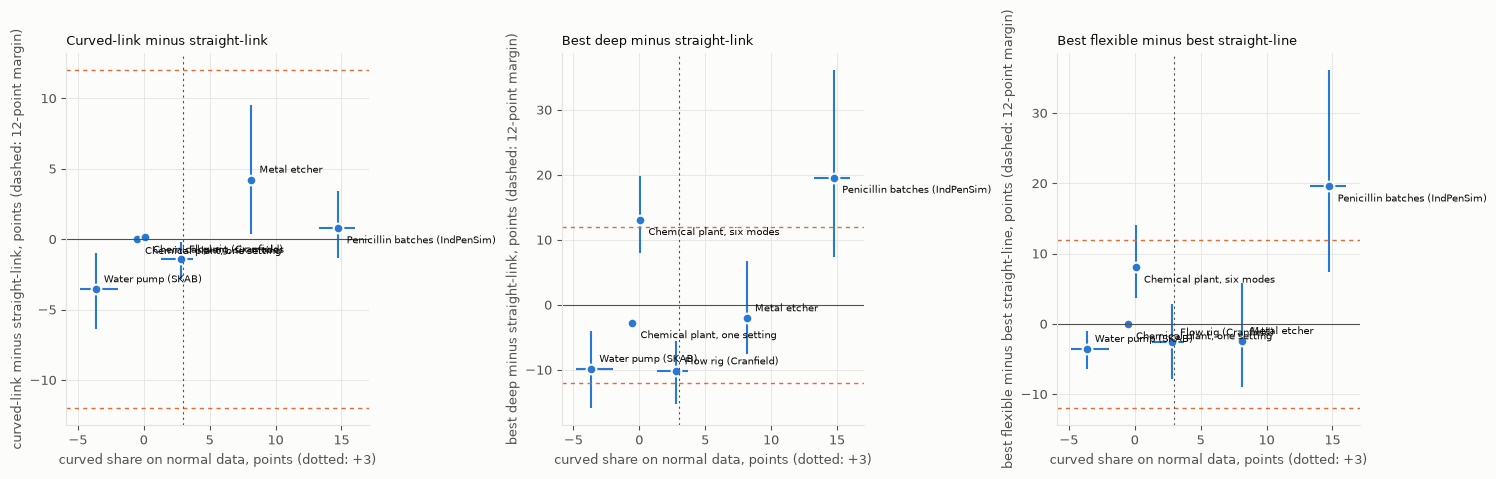

In [4]:
across.chart(frame);

In [5]:
across.same_order(frame)

,pairs in the same order,pairs in opposite orders,pairs tied or missing,pairs
gap,,,,
curved-link minus straight-link,12,3,0,15
best deep minus straight-link,11,4,0,15
best flexible minus best straight-line,11,4,0,15


**What this shows.** In the chart, the datasets line up roughly from bottom left to top right. In the count, **12 of the 15 pairs** put the curved share and the curved-link gap in the same order, and **11 of 15** do so for each of the other two gaps. The one dataset with a large curve *and* a large gain is the penicillin batches. The metal etcher has the second-largest curve and the largest curved-link gap, but that gap is under the margin. The plant in six modes is the exception the other way round: a deep model gains there with no curve at all, because of time, not of shape.

**Read it as a picture, not a test.** Six datasets, very different in size, kind and set-up, with wide ranges on several gaps. One dataset (the penicillin batches) drives most of the agreement. The pattern is consistent with "more curve on normal data, more to gain from flexible models", but six points cannot show it.

## 4. Where each number comes from, and where the setups differ

In [6]:
frame[["curvature from"]]

,curvature from
dataset,
Water pump (SKAB),"notebook 04: the pump's 32 sessions (other/13 left out by the outlier rule), five bloc..."
"Chemical plant, one setting","notebook 04: 20 fault-free Rieth runs, five blocks of time"
Flow rig (Cranfield),"notebook 05: runs T1 + T2, whole visits to a setting held out, staggered"
"Chemical plant, six modes","notebook 06: 30 runs, five rounds of whole runs"
Metal etcher,"notebook 07: 107 wafers, five rounds of whole wafers"
Penicillin batches (IndPenSim),"notebook 08: 90 batches, five rounds of whole batches"


**Where the setups differ** (each number keeps the set-up of its own notebook):

- **How the curved share holds data out.** Five blocks of time within each run for the pump and the plant at one setting (notebook 04); whole visits to a flow setting for the rig (05); whole runs, wafers or batches in five rounds for the six-mode plant, the etcher and the penicillin batches (06 to 08).
- **How the alarm line is set.** Each run's own line for the pump and the rig; a matched-window line from separate fault-free runs for both chemical plants; a line per experiment for the etcher; one line from 30 normal batches for the penicillin batches.
- **How many faults.** 1,000 faulty runs on the plant at one setting and 168 on the plant in six modes, but only 34 pump sessions, 16 rig runs, 21 wafers and 10 batches. The ranges on the last three are wide.
- **Which deep models.** Only the autoencoder and the LSTM; GDN and USAD were dropped by a self-check (notebook 09).
- **The pump's curved share** was measured on its normal stretches with each session's level removed (notebook 04); the others on raw readings.